# C07a — Binoculars NF4 adaptation: fixed 20/34 split

Run in a fresh kernel in the reproduction project, using the **same package versions as your successful NF4 run**. Existing document scores are reused; only missing scores (principally RAID training texts) require model inference. Each document is checkpointed. No text is regenerated.

The published Binoculars ratio is training-free. This experiment instead fits a standardized logistic regression on two saved components: mean NLL and cross-entropy. Compare three detectors on identical 34 held-out NS10 texts:

1. **Frozen ratio**: original NF4 Binoculars score.
2. **RAID-only readout**: classifier fitted on the original RAID training split.
3. **Adapted readout**: the same classifier fitted on RAID training plus 20 randomly selected NS10 examples (AI label).

The RAID-only control separates changing the decision rule from exposure to the attack. Fixed C=1, balanced class weights, no tuning on NS10 test results. Fit the scaler on original RAID training only and share it across both classifiers. Original validation humans calibrate thresholds independently for each detector; the same genre-weighted test humans evaluate both. Random seed 20260923 fixes the 20/34 split. This is one split, not a multi-seed robustness claim.

Keep this described as **adaptation of a Binoculars-feature classifier**, not fine-tuning the Falcon models or retraining the published Binoculars method. NF4 and 512-token prefix scoring remain unchanged.

This revision alternates observer/performer passes in batches of 128. The conservative intermediate-cache bound is about 16 GiB; consumed logits are deleted after final score checkpoints. Model reloads add overhead but do not redownload cached weights. Output paths, split, and scoring contract are unchanged.


In [1]:
# Run once if needed, then restart the kernel. Keep your existing CUDA PyTorch.
# %pip install "transformers==4.44.2" "accelerate==0.34.2" "bitsandbytes>=0.43.3" huggingface_hub safetensors pandas pyarrow matplotlib scikit-learn tqdm psutil


In [2]:
from pathlib import Path
import os,json,hashlib,tempfile,time,getpass,math
from datetime import datetime,timezone
import numpy as np
import pandas as pd
import requests
import matplotlib.pyplot as plt
from tqdm.auto import tqdm
from sklearn.metrics import roc_curve,auc
from IPython.display import display
ROOT=next((p for p in [Path.cwd().resolve(),*Path.cwd().resolve().parents]
 if (p/'results/causal/C05_Ghostbuster_RAID_fixed54').exists()),None)
assert ROOT is not None,'Run inside the reproduction project.'
BASE=ROOT/'results/causal/C02d2_fz118_ghostbuster_raid'
C05=ROOT/'results/causal/C05_Ghostbuster_RAID_fixed54'
NSDIR=ROOT/'results/causal/C06b_NEW_steps5_10_v1'
# Use the output directory of your successful NF4 run.
OUT=ROOT/'results/causal/C07a_Binoculars_NF4_OG_NS10_pinned_v1'
if not (OUT/'contract.json').exists():
 OUT=ROOT/'results/causal/C07a_Binoculars_NF4_OG_NS10_v1'
assert (OUT/'contract.json').exists(), 'Set OUT to your completed NF4 run directory.'
ADAPT=OUT/'adaptation20_34_seed20260923';ADAPT.mkdir(exist_ok=True)
ADAPT_SEED=20260923
OUT.mkdir(parents=True,exist_ok=True)
CACHE=OUT/'responses';CACHE.mkdir(exist_ok=True)
SEED=20260922
MAX_TOKENS=512
DELETE_CONSUMED_LOGITS=True
OBSERVER='tiiuae/falcon-7b'
PERFORMER='tiiuae/falcon-7b-instruct'
LOGITS=OUT/'observer_logits';LOGITS.mkdir(exist_ok=True)
import gc,shutil,importlib.metadata
import torch
from transformers import AutoTokenizer,AutoModelForCausalLM,AutoConfig,BitsAndBytesConfig
from huggingface_hub import HfApi
assert torch.cuda.is_available(), 'This configuration needs a CUDA GPU.'
assert torch.cuda.is_bf16_supported(), 'BF16 required; do not silently change detector precision.'

def text_sha(t):return hashlib.sha256(str(t).encode()).hexdigest()
def file_sha(p):return hashlib.sha256(Path(p).read_bytes()).hexdigest()
def atomic(path,data):
 fd,tmp=tempfile.mkstemp(dir=Path(path).parent,suffix='.tmp')
 try:
  with os.fdopen(fd,'wb') as f:f.write(data);f.flush();os.fsync(f.fileno())
  os.replace(tmp,path)
 finally:
  if os.path.exists(tmp):os.unlink(tmp)
def save_json(obj,p):atomic(p,json.dumps(obj,sort_keys=True,indent=2,allow_nan=False).encode())
def save_csv(df,p):atomic(p,df.to_csv(index=False).encode())
def freeze(obj,p):
 if p.exists():assert json.loads(p.read_text())==obj,'Protocol changed; use a new OUT directory.'
 else:save_json(obj,p)

import bitsandbytes,psutil
print(f"Available RAM: {psutil.virtual_memory().available/2**30:.2f} GiB")
print(f"Free GPU memory: {torch.cuda.mem_get_info()[0]/2**30:.2f} GiB")

SCORE_BATCH_SIZE=128  # bounded observer cache, at most about 16 GiB


/home/user/Downloads/TemporalContextResearch/.venv/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Available RAM: 23.01 GiB
Free GPU memory: 6.68 GiB


In [3]:
# Resolve the exact C05 data universe through saved doc keys.
meta=pd.read_parquet(BASE/'fz118_paired_features.parquet')
corpus=pd.read_parquet(BASE/'paired_corpus.parquet')
assert meta.source_id.is_unique and corpus.source_id.is_unique
raid=meta.loc[meta.dataset.eq('raid'),['source_id','split','label','domain']].copy().reset_index(drop=True)
keys=pd.read_parquet(C05/'raid_all_features.parquet',columns=['doc_key']).doc_key
expected='raid::'+raid.source_id.astype(str)
assert keys.is_unique and set(keys)==set(expected), 'C05 dataset mismatch'
raid['text']=raid.source_id.map(corpus.set_index('source_id').text)
assert raid.text.notna().all() and raid.text.astype(str).str.strip().ne('').all()
assert set(raid.split)=={'train','validation','test'}
ns=pd.read_csv(NSDIR/'NS10_texts.csv',keep_default_na=False).sort_values('case_id').reset_index(drop=True)
assert len(ns)==54 and ns.case_id.is_unique and ns.source_id.is_unique
assert ns.text.map(text_sha).eq(ns.text_sha).all()
rm=raid.set_index('source_id')
assert rm.loc[ns.source_id,'split'].eq('test').all()
assert rm.loc[ns.source_id,'label'].eq(1).all()
assert rm.loc[ns.source_id,'domain'].tolist()==ns.domain.tolist()
og=ns[['case_id','source_id','domain']].copy();og['text']=og.source_id.map(rm.text)


raid['pair_group_id']=raid.source_id.str.split('__',n=1).str[-1]
assert raid.groupby('pair_group_id').split.nunique().eq(1).all()
h=raid.loc[raid.label.eq(0)&raid.split.isin(['validation','test'])].copy()
h['case_id']='';h['stage']='Human'
o=og.assign(stage='OG',split='test',label=1)
n=ns[['case_id','source_id','domain','text']].assign(stage='NS10',split='test',label=1)
train_rows=raid.loc[raid.split.eq('train')].copy()
train_rows['case_id']='';train_rows['stage']='RAID_train'
docs=pd.concat([h,o,n,train_rows],ignore_index=True)
docs['text_sha']=docs.text.map(text_sha)
docs['words']=docs.text.str.split().str.len()
unique=docs[['text_sha','text','words']].drop_duplicates('text_sha').reset_index(drop=True)
display(docs.groupby(['stage','split']).size().rename('documents'))

# Release larger source tables before model loading; docs/unique retain evaluation texts.
del meta,corpus,raid,rm,h,o,n,keys,expected
gc.collect()

# Persist the split before scoring or examining adaptation outcomes.
case_ids=sorted(ns.case_id.astype(str).tolist())
chosen=sorted(np.random.default_rng(ADAPT_SEED).choice(case_ids,size=20,replace=False).tolist())
held=sorted(set(case_ids)-set(chosen))
assert len(chosen)==20 and len(held)==34
freeze(dict(seed=ADAPT_SEED,adaptation_cases=chosen,test_cases=held),ADAPT/'split.json')
roles=ns[['case_id','source_id','domain','text_sha']].copy()
roles['role']=np.where(roles.case_id.isin(chosen),'adaptation','test')
save_csv(roles,ADAPT/'case_roles.csv')
# Exact duplicate texts across fitting/evaluation would compromise this test.
fit_hashes=set(docs.loc[docs.stage.eq('RAID_train')| (docs.stage.eq('NS10')&docs.case_id.isin(chosen)),'text_sha'])
eval_hashes=set(docs.loc[docs.stage.eq('Human')| (docs.stage.eq('NS10')&docs.case_id.isin(held)),'text_sha'])
assert not fit_hashes & eval_hashes, 'Exact text overlap across fit/evaluation: inspect manifest before proceeding.'
display(roles.groupby(['role','domain']).size().rename('cases'))
del train_rows


stage       split     
Human       test           138
            validation     135
NS10        test            54
OG          test            54
RAID_train  train         1272
Name: documents, dtype: int64

role        domain   
adaptation  abstracts    3
            books        2
            news         7
            recipes      4
            reddit       2
            wiki         2
test        abstracts    7
            books        5
            news         5
            recipes      5
            reddit       4
            reviews      1
            wiki         7
Name: cases, dtype: int64

In [4]:
# Freeze model revisions and score/cache contract before downloading weights.
revpath=OUT/'model_revisions.json'
if revpath.exists():revisions=json.loads(revpath.read_text())
else:
 prior=ROOT/'results/causal/C07a_Binoculars_OG_NS10_v1/model_revisions.json'
 revisions=json.loads(prior.read_text()) if prior.exists() else {name:HfApi().model_info(name).sha for name in [OBSERVER,PERFORMER]}
 save_json(revisions,revpath)
tok=AutoTokenizer.from_pretrained(OBSERVER,revision=revisions[OBSERVER])
other=AutoTokenizer.from_pretrained(PERFORMER,revision=revisions[PERFORMER])
assert tok.vocab==other.vocab,'The model tokenizers must share their vocabulary.'
if tok.pad_token is None:tok.pad_token=tok.eos_token
del other
contract=dict(version='C07a_Binoculars_NF4_v1',quantization='NF4_double_quant',metric_device='cpu',models=revisions,max_tokens=MAX_TOKENS,
 dtype='bfloat16',attention='eager',metric='official_mean_nll_over_cross_entropy',
 code_commit='c8ae2f90d50ee696418bc71d8d9e5020e5f9d7b8',
 runtime={p:importlib.metadata.version(p) for p in ['torch','transformers','accelerate','bitsandbytes']},
 inputs={str(p.relative_to(ROOT)):file_sha(p) for p in [BASE/'fz118_paired_features.parquet',
 BASE/'paired_corpus.parquet',C05/'raid_all_features.parquet',NSDIR/'NS10_texts.csv']})
freeze(contract,OUT/'contract.json');signature=text_sha(json.dumps(contract,sort_keys=True))
def cache_path(sha):return CACHE/(text_sha(signature+sha)+'.json')
def logit_path(sha):return LOGITS/(text_sha(signature+sha)+'.pt')
def encode(text):return tok(text,return_tensors='pt',truncation=True,max_length=MAX_TOKENS)
def complete(sha):
 p=cache_path(sha)
 if not p.exists():return False
 r=json.loads(p.read_text())
 assert r['contract']==signature and r['text_sha']==sha and np.isfinite(r['Binoculars_score'])
 return True
lengths={r.text_sha:len(tok(r.text,truncation=False)['input_ids']) for r in unique.itertuples()}
assert min(lengths.values())>=2,'A document has fewer than two tokens; inspect rather than silently excluding it.'
docs['total_tokens']=docs.text_sha.map(lengths)
docs['scored_tokens']=docs.total_tokens.clip(upper=MAX_TOKENS)
docs['truncated']=docs.total_tokens.gt(MAX_TOKENS)
save_csv(docs.drop(columns='text'),ADAPT/'score_manifest.csv')
display(docs.groupby('stage').agg(documents=('text_sha','size'),truncated=('truncated','sum')))
vocab=AutoConfig.from_pretrained(OBSERVER,revision=revisions[OBSERVER]).vocab_size
missing=[r for r in unique.to_dict('records') if not complete(r['text_sha'])]
next_batch=missing[:SCORE_BATCH_SIZE]
needed=sum(min(lengths[r['text_sha']],MAX_TOKENS)*vocab*4 for r in next_batch if not logit_path(r['text_sha']).exists())
print(f'Pending scores: {len(missing)}; next-batch extra observer cache: {needed/2**30:.2f} GiB')
print(f'Free disk space: {shutil.disk_usage(OUT).free/2**30:.1f} GiB')
assert shutil.disk_usage(OUT).free>needed+2*2**30,'Insufficient disk space for next batch; reduce SCORE_BATCH_SIZE.'


/home/user/Downloads/TemporalContextResearch/.venv/lib/python3.12/site-packages/transformers/tokenization_utils_base.py:1601: FutureWarning: `clean_up_tokenization_spaces` was not set. It will be set to `True` by default. This behavior will be depracted in transformers v4.45, and will be then set to `False` by default. For more details check this issue: https://github.com/huggingface/transformers/issues/31884
  warnings.warn(


,documents,truncated
stage,,
Human,273,11
NS10,54,25
OG,54,1
RAID_train,1272,51


Pending scores: 1272; next-batch extra observer cache: 10.07 GiB
Free disk space: 80.9 GiB


In [5]:
# Default metric functions from the pinned official implementation (see reference above).
import numpy as np
import torch
import transformers

ce_loss_fn = torch.nn.CrossEntropyLoss(reduction="none")
softmax_fn = torch.nn.Softmax(dim=-1)


def perplexity(encoding: transformers.BatchEncoding,
               logits: torch.Tensor,
               median: bool = False,
               temperature: float = 1.0):
    shifted_logits = logits[..., :-1, :].contiguous() / temperature
    shifted_labels = encoding.input_ids[..., 1:].contiguous()
    shifted_attention_mask = encoding.attention_mask[..., 1:].contiguous()

    if median:
        ce_nan = (ce_loss_fn(shifted_logits.transpose(1, 2), shifted_labels).
                  masked_fill(~shifted_attention_mask.bool(), float("nan")))
        ppl = np.nanmedian(ce_nan.cpu().float().numpy(), 1)

    else:
        ppl = (ce_loss_fn(shifted_logits.transpose(1, 2), shifted_labels) *
               shifted_attention_mask).sum(1) / shifted_attention_mask.sum(1)
        ppl = ppl.to("cpu").float().numpy()

    return ppl


def entropy(p_logits: torch.Tensor,
            q_logits: torch.Tensor,
            encoding: transformers.BatchEncoding,
            pad_token_id: int,
            median: bool = False,
            sample_p: bool = False,
            temperature: float = 1.0):
    vocab_size = p_logits.shape[-1]
    total_tokens_available = q_logits.shape[-2]
    p_scores, q_scores = p_logits / temperature, q_logits / temperature

    p_proba = softmax_fn(p_scores).view(-1, vocab_size)

    if sample_p:
        p_proba = torch.multinomial(p_proba.view(-1, vocab_size), replacement=True, num_samples=1).view(-1)

    q_scores = q_scores.view(-1, vocab_size)

    ce = ce_loss_fn(input=q_scores, target=p_proba).view(-1, total_tokens_available)
    padding_mask = (encoding.input_ids != pad_token_id).type(torch.uint8)

    if median:
        ce_nan = ce.masked_fill(~padding_mask.bool(), float("nan"))
        agg_ce = np.nanmedian(ce_nan.cpu().float().numpy(), 1)
    else:
        agg_ce = (((ce * padding_mask).sum(1) / padding_mask.sum(1)).to("cpu").float().numpy())

    return agg_ce


In [6]:
def save_tensor(obj,path):
 fd,tmp=tempfile.mkstemp(dir=path.parent,suffix='.tmp');os.close(fd)
 try:
  torch.save(obj,tmp)
  with open(tmp,'rb') as f:os.fsync(f.fileno())
  os.replace(tmp,path)
 finally:
  if os.path.exists(tmp):os.unlink(tmp)
def load_model(name):
 print('Loading',name,flush=True)
 quant=BitsAndBytesConfig(load_in_4bit=True,bnb_4bit_quant_type='nf4',
  bnb_4bit_use_double_quant=True,bnb_4bit_compute_dtype=torch.bfloat16)
 model=AutoModelForCausalLM.from_pretrained(name,revision=revisions[name],
  torch_dtype=torch.bfloat16,quantization_config=quant,device_map={'':0},
  low_cpu_mem_usage=True,attn_implementation='eager')
 print(f'Model footprint: {model.get_memory_footprint()/2**30:.2f} GiB',flush=True)
 model.eval();return model
@torch.inference_mode()
def forward(model,encoding):
 # Accelerate dispatch hooks move inputs to the execution device as necessary.
 device=model.get_input_embeddings().weight.device
 if device.type=='meta':device=torch.device('cuda:0')
 return model(**{k:v.to(device) for k,v in encoding.items()},use_cache=False).logits.detach().cpu()



In [7]:
# Alternate model passes over bounded batches; final scores retain the same contract.
# Existing completed scores and observer logits are reusable.
all_pending=[r for r in unique.to_dict('records') if not complete(r['text_sha'])]
for start in range(0,len(all_pending),SCORE_BATCH_SIZE):
 batch=all_pending[start:start+SCORE_BATCH_SIZE]
 print(f'Batch {start//SCORE_BATCH_SIZE+1}: {len(batch)} documents',flush=True)
 observer_pending=[r for r in batch if not complete(r['text_sha']) and not logit_path(r['text_sha']).exists()]
 needed=sum(min(lengths[r['text_sha']],MAX_TOKENS)*vocab*4 for r in observer_pending)
 assert shutil.disk_usage(OUT).free>needed+2*2**30,'Disk space low; reduce SCORE_BATCH_SIZE and rerun.'
 model=None
 try:
  if observer_pending:model=load_model(OBSERVER)
  for r in tqdm(observer_pending,desc='Observer batch'):
   enc=encode(r['text']);p=forward(model,enc)
   save_tensor(dict(contract=signature,text_sha=r['text_sha'],ids=enc.input_ids,logits=p),logit_path(r['text_sha']))
   del p,enc
 finally:
  del model;gc.collect();torch.cuda.empty_cache()
 model=None
 try:
  pending=[r for r in batch if not complete(r['text_sha'])]
  if pending:model=load_model(PERFORMER)
  for r in tqdm(pending,desc='Performer batch'):
   started=time.perf_counter();enc=encode(r['text'])
   saved=torch.load(logit_path(r['text_sha']),map_location='cpu',weights_only=True)
   assert saved['contract']==signature and saved['text_sha']==r['text_sha']
   assert torch.equal(saved['ids'],enc.input_ids)
   q=forward(model,enc);p=saved['logits']
   with torch.inference_mode():
    numerator=float(perplexity(enc,q)[0]);denominator=float(entropy(p,q,enc,tok.pad_token_id)[0])
   assert np.isfinite(numerator) and np.isfinite(denominator) and denominator>0
   ratio=numerator/denominator
   save_json(dict(contract=signature,text_sha=r['text_sha'],Binoculars_score=ratio,AI_score=-ratio,
    mean_nll=numerator,cross_entropy=denominator,scored_tokens=int(enc.input_ids.shape[1]),
    total_tokens=lengths[r['text_sha']],seconds=time.perf_counter()-started),cache_path(r['text_sha']))
   # Delete only after the final score is durably saved.
   logit_path(r['text_sha']).unlink(missing_ok=True)
   del p,q,enc,saved
 finally:
  del model;gc.collect();torch.cuda.empty_cache()
 print(f'Completed {min(start+SCORE_BATCH_SIZE,len(all_pending))}/{len(all_pending)} initially pending scores',flush=True)
records=[]
for r in docs.drop(columns='text').to_dict('records'):
 assert complete(r['text_sha'])
 records.append({**r,**json.loads(cache_path(r['text_sha']).read_text())})
scored=pd.DataFrame(records);save_csv(scored,ADAPT/'all_scores.csv')
print('Saved training and evaluation component scores.')


Batch 1: 128 documents
Loading tiiuae/falcon-7b


Loading checkpoint shards: 100%|████████████████████████████████████████████████████████████████████| 2/2 [00:05<00:00,  2.85s/it]

Model footprint: 3.65 GiB



Observer batch: 100%|███████████████████████████████████████████████████████████████████████████| 128/128 [00:54<00:00,  2.35it/s]


Loading tiiuae/falcon-7b-instruct


...

Loading tiiuae/falcon-7b-instruct


Loading checkpoint shards: 100%|████████████████████████████████████████████████████████████████████| 2/2 [00:06<00:00,  3.34s/it]

Model footprint: 3.65 GiB



Performer batch: 100%|██████████████████████████████████████████████████████████████████████████| 120/120 [01:06<00:00,  1.81it/s]


Completed 1272/1272 initially pending scores
Saved training and evaluation component scores.


In [8]:
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import roc_auc_score
FEATURES=['mean_nll','cross_entropy']
T=scored.loc[scored.stage.eq('RAID_train')].copy()
A=scored.loc[scored.stage.eq('NS10')&scored.case_id.isin(chosen)].copy()
E=scored.loc[scored.stage.eq('NS10')&scored.case_id.isin(held)].sort_values('case_id').copy()
H=scored.loc[scored.stage.eq('Human')].copy()
assert len(A)==20 and len(E)==34 and set(T.label)=={0,1}
assert np.isfinite(scored[FEATURES].to_numpy(dtype=float)).all()
protocol=dict(features=FEATURES,C=1.0,class_weight='balanced',solver='lbfgs',
 scaler_fit='original_RAID_train',seed=ADAPT_SEED,score_contract=signature,
 sklearn=importlib.metadata.version('scikit-learn'),adaptation_cases=chosen,test_cases=held)
freeze(protocol,ADAPT/'protocol.json')
scaler=StandardScaler().fit(T[FEATURES])
models={}
for name,fit in [('RAID-only readout',T),('Adapted readout',pd.concat([T,A],ignore_index=True))]:
 m=LogisticRegression(C=1.0,class_weight='balanced',solver='lbfgs',max_iter=5000,random_state=ADAPT_SEED)
 m.fit(scaler.transform(fit[FEATURES]),fit.label.astype(int))
 assert int(m.n_iter_.max())<5000, 'Classifier did not converge.'
 models[name]=m
 save_json(dict(features=FEATURES,classes=m.classes_.tolist(),coef=m.coef_.tolist(),
  intercept=m.intercept_.tolist(),scaler_mean=scaler.mean_.tolist(),scaler_scale=scaler.scale_.tolist(),
  training_rows=len(fit)),ADAPT/(name.replace(' ','_')+'_model.json'))
print('Fitted RAID-only and adapted readouts. Falcon models remain frozen.')

def get_scores(frame):
 result={'Frozen ratio':frame.AI_score.to_numpy(dtype=float)}
 for name,m in models.items():result[name]=m.decision_function(scaler.transform(frame[FEATURES]))
 return result
mix=E.domain.value_counts(normalize=True)
def human_reference(split):
 q=H.loc[H.split.eq(split)&H.domain.isin(mix.index)].copy()
 counts=q.domain.value_counts();assert set(mix.index)<=set(counts.index)
 q['weight']=[mix[d]/counts[d] for d in q.domain]
 assert np.isclose(q.weight.sum(),1)
 return q
V=human_reference('validation');B=human_reference('test')
es,vs,bs=get_scores(E),get_scores(V),get_scores(B)
for frame,values,filename in [(E,es,'NS10_test34_scores.csv'),(V,vs,'validation_human_scores.csv'),(B,bs,'test_human_scores.csv')]:
 export=frame.drop(columns=['contract'],errors='ignore').copy()
 for name,value in values.items():export[name]=value
 save_csv(export,ADAPT/filename)
summary=[];stairs=[];ops=[];contrib={}
for name in es:
 ai,human,validation=es[name],bs[name],vs[name]
 weights=B.weight.to_numpy()
 contributions=(((ai[:,None]>human)+.5*(ai[:,None]==human))*weights).sum(axis=1)
 contrib[name]=contributions
 summary.append(dict(detector=name,cases=len(ai),AUROC=float(contributions.mean())))
 cuts=np.r_[np.inf,np.unique(validation)[::-1],-np.inf]
 st=pd.DataFrame(dict(detector=name,threshold=cuts,
  calibration_FPR=[V.weight.to_numpy()[validation>c].sum() for c in cuts],
  test_FPR=[weights[human>c].sum() for c in cuts],TPR=[(ai>c).mean() for c in cuts]))
 stairs.append(st)
 for target in [0,.001,.005,.01,.02,.05,.1,.2,.5,1.]:
  row=st.loc[st.calibration_FPR<=target+1e-12].iloc[-1].to_dict()
  row['target_FPR']=target;ops.append(row)
summary=pd.DataFrame(summary);staircase=pd.concat(stairs,ignore_index=True);operating=pd.DataFrame(ops)
for frame,filename in [(summary,'summary.csv'),(staircase,'TPR_staircase.csv'),(operating,'operating_points.csv')]:save_csv(frame,ADAPT/filename)
display(summary.round(6));display(operating.loc[operating.target_FPR.isin([.01,.05,.1])].round(6))
# Resample identical attack cases for both detectors, holding test humans fixed.
ix=np.random.default_rng(ADAPT_SEED).integers(0,34,size=(10000,34))
rows=[]
for left,right in [('Frozen ratio','Adapted readout'),('RAID-only readout','Adapted readout'),('Frozen ratio','RAID-only readout')]:
 d=contrib[right]-contrib[left];lo,hi=np.quantile(d[ix].mean(axis=1),[.025,.975])
 rows.append(dict(comparison=right+' minus '+left,mean_AUROC_delta=d.mean(),ci_low=lo,ci_high=hi,
  increased=int((d>0).sum()),decreased=int((d<0).sum()),unchanged=int((d==0).sum())))
changes=pd.DataFrame(rows);save_csv(changes,ADAPT/'paired_AUROC_changes.csv');display(changes.round(6))
print('Intervals condition on the trained models, the chosen 20/34 split and fixed human references.')


Fitted RAID-only and adapted readouts. Falcon models remain frozen.


,detector,cases,AUROC
0,Frozen ratio,34,0.684260
1,RAID-only readout,34,0.672084
2,Adapted readout,34,0.678159


,detector,threshold,calibration_FPR,test_FPR,TPR,target_FPR
3,Frozen ratio,-0.865854,0.005882,0.017839,0.323529,0.01
5,Frozen ratio,-0.907975,0.044258,0.066034,0.441176,0.05
6,Frozen ratio,-0.922078,0.098667,0.141103,0.470588,0.10
13,RAID-only readout,0.386168,0.005882,0.000000,0.352941,0.01
15,RAID-only readout,-0.317846,0.046613,0.067201,0.470588,0.05
16,RAID-only readout,-0.610913,0.098667,0.149273,0.470588,0.10
23,Adapted readout,0.401231,0.005882,0.000000,0.352941,0.01
25,Adapted readout,-0.286238,0.046613,0.067201,0.441176,0.05
26,Adapted readout,-0.542819,0.098667,0.143391,0.470588,0.10


,comparison,mean_AUROC_delta,ci_low,ci_high,increased,decreased,unchanged
0,Adapted readout minus Frozen ratio,-0.006100,-0.017103,0.003447,17,12,5
1,Adapted readout minus RAID-only readout,0.006075,0.001869,0.011251,10,3,21
2,RAID-only readout minus Frozen ratio,-0.012175,-0.025218,-0.000823,15,15,4


Intervals condition on the trained models, the chosen 20/34 split and fixed human references.


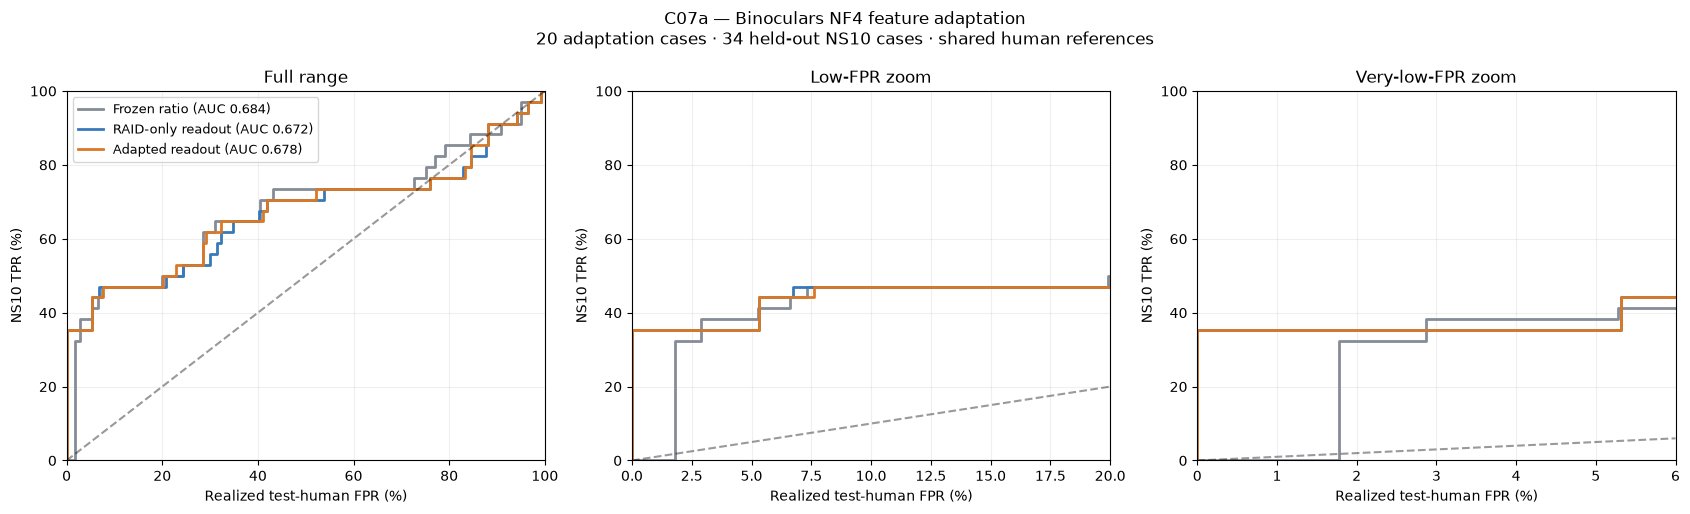

Saved: ../results/causal/C07a_Binoculars_NF4_OG_NS10_pinned_v1/adaptation20_34_seed20260923
Adapted minus RAID-only isolates exposure to NS10 within this fixed readout protocol.


In [9]:
colors={'Frozen ratio':'#858C96','RAID-only readout':'#3979B9','Adapted readout':'#D97928'}
fig,axs=plt.subplots(1,3,figsize=(17,5.2))
for ax,(xl,yl,title) in zip(axs,[((0,100),(0,100),'Full range'),((0,20),(0,100),'Low-FPR zoom'),((0,6),(0,100),'Very-low-FPR zoom')]):
 for name,color in colors.items():
  q=staircase.loc[staircase.detector.eq(name)]
  score=float(summary.loc[summary.detector.eq(name),'AUROC'].iloc[0])
  ax.step(100*q.test_FPR,100*q.TPR,where='post',color=color,lw=2,label=f'{name} (AUC {score:.3f})')
 hi=min(xl[1],yl[1]);ax.plot([0,hi],[0,hi],'--',color='black',alpha=.4)
 ax.set(xlim=xl,ylim=yl,title=title,xlabel='Realized test-human FPR (%)',ylabel='NS10 TPR (%)');ax.grid(alpha=.2)
axs[0].legend(fontsize=9)
fig.suptitle('C07a — Binoculars NF4 feature adaptation\n20 adaptation cases · 34 held-out NS10 cases · shared human references')
fig.tight_layout()
for folder in [ADAPT,ROOT/'figures']:
 folder.mkdir(exist_ok=True,parents=True)
 for ext in ['png','pdf']:fig.savefig(folder/('C07a_Binoculars_NF4_adaptation20_34.'+ext),dpi=300,bbox_inches='tight')
plt.show();plt.close(fig)
print('Saved:',ADAPT)
print('Adapted minus RAID-only isolates exposure to NS10 within this fixed readout protocol.')
